# Module 3: Fracture Position Detection — YOLO26

---
## Check Cuda Compatability

In [1]:
import os
# I need this to run torch on my computer, comment it according to your GPU, please do not delete, comment ~Omar
os.environ["HSA_OVERRIDE_GFX_VERSION"] = "11.0.0"

In [2]:
import torch
print(torch.__version__)
print("CUDA available:", torch.cuda.is_available())
import gc
import torch
gc.collect()
if torch.cuda.is_available():
    # Limit GPU memory to 90%
    torch.cuda.set_per_process_memory_fraction(0.9)
    dev = torch.cuda.get_device_properties(0)
    torch.cuda.empty_cache()
    print(f"GPU: {dev.name}")
    print(f"VRAM: {dev.total_memory / 1024**3:.1f} GB")
    print(f"GPU Memory Limit: 90% of total VRAM")


2.5.1+rocm6.1
CUDA available: True
GPU: AMD Radeon Graphics
VRAM: 16.0 GB
GPU Memory Limit: 90% of total VRAM


## Load Dataset

In [3]:
from pathlib import Path

notebook_folderPath = Path().absolute()

MERGED_DIR = notebook_folderPath / "input" / "Base Dataset"

print(f"MERGED_DIR: {MERGED_DIR}")

MERGED_DIR: /home/omarriad/Documents/10th Sem/DMET 1067 - Deep Learning in Computer Vision/Project Milestone 2/Model Fine-tuning/Models Workspaces/X-Ray Bounding Box Extraction/YOLO26/input/Base Dataset


## Imports & Configuration

In [4]:
import os
import csv
import yaml
from torch import cuda
import cv2
import numpy as np
import matplotlib.patches as patches
import matplotlib.pyplot as plt
from ultralytics import YOLO
from tqdm import tqdm

# Output configuration
WORKSPACE_DIR = notebook_folderPath
RUN_NAME = "YOLOv8 Tuesday Night"


# Hyperparameters and training configuration
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
PIN_MEMORY = cuda.is_available()


EARLY_STOPPING_PATIENCE = 12
BATCH_SIZE = 4          
NUM_WORKERS = 2   
EPOCHS = 75
LEARNING_RATE = 2e-5

MODEL_SAVE_PATH = WORKSPACE_DIR/ "output" / "final_model" /"best_model.pth"

os.makedirs(MODEL_SAVE_PATH.parent, exist_ok=True)


/home/omarriad/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## Prepare Dataset

In [5]:
import os
import random
import shutil
from pathlib import Path

def split_bg_from_non_bg(dataset_dir="/workspace/Merged_Fracture", split="train", keep_bg_count=500, random_seed=42):
    images_dir = Path(dataset_dir) / split / "images"
    labels_dir = Path(dataset_dir) / split / "labels"
    
    # Create a backup folder for the excess backgrounds
    backup_img_dir = Path(dataset_dir) / f"{split}_excess_bg" / "images"
    backup_lbl_dir = Path(dataset_dir) / f"{split}_excess_bg" / "labels"
    backup_img_dir.mkdir(parents=True, exist_ok=True)
    backup_lbl_dir.mkdir(parents=True, exist_ok=True)

    background_images = []
    
    # Find all images
    for img_path in images_dir.glob("*.*"):
        if img_path.suffix.lower() not in [".jpg", ".png", ".jpeg"]: continue
            
        lbl_path = labels_dir / (img_path.stem + ".txt")
        
        # If label doesn't exist or is empty, it's a background!
        if not lbl_path.exists() or lbl_path.stat().st_size == 0:
            background_images.append((img_path, lbl_path))

    print(f"Found {len(background_images)} background images in the '{split}' set.")
    
    if len(background_images) <= keep_bg_count:
        print("Dataset is already balanced!")
        return

    # Shuffle and pick the ones to move
    random.seed(random_seed)
    random.shuffle(background_images)
    excess_bgs = background_images[keep_bg_count:]
    
    print(f"Moving {len(excess_bgs)} excess background images out of the training set...")
    
    for img_path, lbl_path in excess_bgs:
        shutil.move(str(img_path), str(backup_img_dir / img_path.name))
        if lbl_path.exists():
            shutil.move(str(lbl_path), str(backup_lbl_dir / lbl_path.name))
            
    print(f"✅ Done! Your '{split}' set is now balanced.")

# Run the balancer!
split_bg_from_non_bg(dataset_dir=MERGED_DIR, split="train", keep_bg_count=0)
split_bg_from_non_bg(dataset_dir=MERGED_DIR, split="val", keep_bg_count=0)
split_bg_from_non_bg(dataset_dir=MERGED_DIR, split="test", keep_bg_count=0)

Found 0 background images in the 'train' set.
Dataset is already balanced!
Found 0 background images in the 'val' set.
Dataset is already balanced!
Found 0 background images in the 'test' set.
Dataset is already balanced!


### Split dataset into 70/20/10

In [6]:
def balance_splits(dataset_dir="/workspace/Merged_Fracture", output_dir=None, splits=["train", "val", "test"], split_ratio = [0.7, 0.2, 0.1], bg_ratio=0.3, random_seed=42):
    if len(splits) != len(split_ratio):
        raise ValueError("Length of splits and split_ratio must be the same.")
    
    if output_dir is None:
        raise ValueError("Please provide an output directory to save the balanced dataset.")
    
    total_non_bg = len(list((dataset_dir / "train" / "labels").glob("*.txt"))) + len(list((dataset_dir / "val" / "labels").glob("*.txt"))) + len(list((dataset_dir / "test" / "labels").glob("*.txt")))
    total_bg = len(list((dataset_dir / "train_excess_bg" / "images").glob("*.*"))) + len(list((dataset_dir / "val_excess_bg" / "images").glob("*.*"))) + len(list((dataset_dir / "test_excess_bg" / "images").glob("*.*")))
    print(f"Total non-background images across all splits: {total_non_bg}")
    print(f"Total background images across all splits: {total_bg}")
    
    target_train_non_bg = total_non_bg * split_ratio[0]
    target_val_non_bg = total_non_bg * split_ratio[1]
    target_test_non_bg = total_non_bg * split_ratio[2]

    target_train_bg = round(target_train_non_bg * bg_ratio / (1 - bg_ratio))
    target_val_bg = round(target_val_non_bg * bg_ratio / (1 - bg_ratio))
    target_test_bg = round(target_test_non_bg * bg_ratio / (1 - bg_ratio))

    if target_train_bg + target_val_bg + target_test_bg > total_bg:
        raise ValueError("Not enough background images to meet the desired bg_ratio. Please adjust the bg_ratio or provide more background images.")

    total_train = total_non_bg * split_ratio[0] + target_train_bg
    total_val = total_non_bg * split_ratio[1] + target_val_bg
    total_test = total_non_bg * split_ratio[2] + target_test_bg

    print(f"Target Dataset and Background Counts:")
    print(f"  Train: {target_train_bg} bg/{int(total_train)} total")
    print(f"  Val: {target_val_bg} bg/{int(total_val)} total")
    print(f"  Test: {target_test_bg} bg/{int(total_test)} total")

    print("\nBalancing splits...")

    all_non_bg_images_with_labels = []
    for split in splits:
        split_images_dir = dataset_dir / split / "images"
        for image_path in split_images_dir.glob("*.*"):
            label_path = dataset_dir / split / "labels" / (image_path.stem + ".txt")
            if not label_path.exists():
                raise ValueError(f"Label file {label_path} does not exist for image {image_path}.")
            all_non_bg_images_with_labels.append((image_path, label_path))

    all_bg_images_with_labels = []
    for split in splits:
        excess_bg_images_dir = dataset_dir / f"{split}_excess_bg" / "images"
        excess_bg_labels_dir = dataset_dir / f"{split}_excess_bg" / "labels"
        for image_path in excess_bg_images_dir.glob("*.*"):
            label_path = excess_bg_labels_dir / (image_path.stem + ".txt")
            if not label_path.exists():
                raise ValueError(f"Label file {label_path} does not exist for background image {image_path}.")
            all_bg_images_with_labels.append((image_path, label_path))

    random.seed(random_seed)
    random.shuffle(all_non_bg_images_with_labels)
    random.shuffle(all_bg_images_with_labels)

    for tuple in [(target_train_non_bg, target_train_bg, "train"), (target_val_non_bg, target_val_bg, "val"), (target_test_non_bg, target_test_bg, "test")]:
        #print(f"Processing split '{tuple[2]}' with target {int(tuple[0])} non-bg and {tuple[1]} bg images...")
        images = []
        images.extend(all_non_bg_images_with_labels[:int(tuple[0])])
        all_non_bg_images_with_labels = all_non_bg_images_with_labels[int(tuple[0]):]
        images.extend(all_bg_images_with_labels[:int(tuple[1])])
        all_bg_images_with_labels = all_bg_images_with_labels[int(tuple[1]):]

        #shuffle and copy to output dir
        random.shuffle(images)
        for img_path, lbl_path in images:
            dest_img_path = Path(output_dir) / tuple[2] / "images" / img_path.name
            dest_lbl_path = Path(output_dir) / tuple[2] / "labels" / lbl_path.name
            dest_img_path.parent.mkdir(parents=True, exist_ok=True)
            dest_lbl_path.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy(str(img_path), str(dest_img_path))
            shutil.copy(str(lbl_path), str(dest_lbl_path))


CLEANED_DATASET_DIR = MERGED_DIR.parent / "Balanced_Dataset"
os.makedirs(CLEANED_DATASET_DIR, exist_ok=True)

balance_splits(dataset_dir=MERGED_DIR, output_dir=CLEANED_DATASET_DIR, splits=["train", "val", "test"], split_ratio = [0.7, 0.2, 0.1], bg_ratio=0.085, random_seed=42)

Total non-background images across all splits: 4351
Total background images across all splits: 12321
Target Dataset and Background Counts:
  Train: 283 bg/3328 total
  Val: 81 bg/951 total
  Test: 40 bg/475 total

Balancing splits...


### Validate Existing Merged Dataset

No source datasets are copied or merged in this notebook.

In [7]:
def find_val_split(root: Path) -> str:
    if (root / "val" / "images").exists():
        return "val"
    if (root / "valid" / "images").exists():
        return "valid"
    return "val"

def count_images(folder: Path) -> int:
    return len(list(folder.glob("*.jpg"))) + len(list(folder.glob("*.png")))

root = Path(CLEANED_DATASET_DIR)
val_split = find_val_split(root)

splits = ["train", val_split, "test"]
print("=== Validating merged dataset ===")
total = 0
for split in splits:
    img_dir = root / split / "images"
    lbl_dir = root / split / "labels"

    if not img_dir.exists():
        print(f"  Missing: {img_dir}")
        continue
    if not lbl_dir.exists():
        print(f"  Missing: {lbl_dir}")
        continue

    n = count_images(img_dir)
    total += n
    print(f"  {split:<5}: {n:>5} images")

if total == 0:
    raise ValueError(
        "No images found in merged dataset. "
        "Expected folders like train/images, val(or valid)/images, test/images."
    )

print(f"\nMerged dataset looks ready. Total images found: {total}")

=== Validating merged dataset ===
  train:  3328 images
  val  :   951 images
  test :   475 images

Merged dataset looks ready. Total images found: 4754


### Dataset Summary

Merged Dataset Summary
-----------------------------------
  Train :  3328 images
  Val  :   951 images
  Test  :   475 images
-----------------------------------
  Total :  4754 images


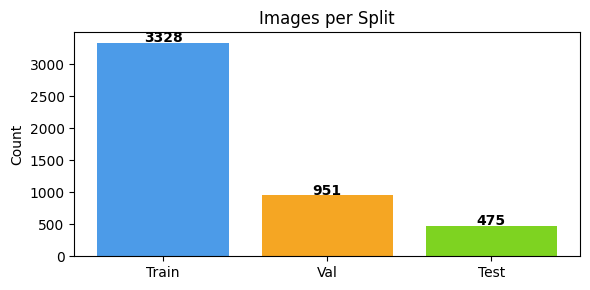

In [8]:
def resolve_val_split(root: Path) -> str:
    if (root / "val" / "images").exists():
        return "val"
    if (root / "valid" / "images").exists():
        return "valid"
    return "val"

def count_split(split):
    img_dir = Path(CLEANED_DATASET_DIR) / split / "images"
    if not img_dir.exists():
        return 0
    return len(list(img_dir.glob("*.jpg"))) + len(list(img_dir.glob("*.png")))

val_split = resolve_val_split(Path(CLEANED_DATASET_DIR))

train_n = count_split("train")
val_n   = count_split(val_split)
test_n  = count_split("test")
total   = train_n + val_n + test_n

print("Merged Dataset Summary")
print("-" * 35)
print(f"  Train : {train_n:>5} images")
print(f"  {val_split.capitalize():<5}: {val_n:>5} images")
print(f"  Test  : {test_n:>5} images")
print("-" * 35)
print(f"  Total : {total:>5} images")

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(["Train", val_split.capitalize(), "Test"], [train_n, val_n, test_n],
       color=["#4C9BE8", "#F5A623", "#7ED321"])
ax.set_title("Images per Split")
ax.set_ylabel("Count")
for i, v in enumerate([train_n, val_n, test_n]):
    ax.text(i, v + 10, str(v), ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

### Write `data.yaml`

In [9]:
def write_yaml():
    root = Path(CLEANED_DATASET_DIR)
    val_split = "val" if (root / "val" / "images").exists() else "valid"
    config = {
        "path": str(CLEANED_DATASET_DIR),
        "train": "train/images",
        "val": f"{val_split}/images",
        "test": "test/images",
        "nc": 1,
        "names": ["fracture"],
        "image_split": {
            "train": train_n,
            "val": val_n,
            "test": test_n
        }
    }
    yaml_path = os.path.join(CLEANED_DATASET_DIR, "data.yaml")
    with open(yaml_path, "w") as f:
        yaml.dump(config, f, default_flow_style=False, sort_keys=False)
    print(f"data.yaml written to:\n   {yaml_path}")
    print("\nContents:")
    print("-" * 30)
    with open(yaml_path) as f:
        print(f.read())
    return yaml_path

YAML_PATH = write_yaml()

data.yaml written to:
   /home/omarriad/Documents/10th Sem/DMET 1067 - Deep Learning in Computer Vision/Project Milestone 2/Model Fine-tuning/Models Workspaces/X-Ray Bounding Box Extraction/YOLO26/input/Balanced_Dataset/data.yaml

Contents:
------------------------------
path: /home/omarriad/Documents/10th Sem/DMET 1067 - Deep Learning in Computer Vision/Project
  Milestone 2/Model Fine-tuning/Models Workspaces/X-Ray Bounding Box Extraction/YOLO26/input/Balanced_Dataset
train: train/images
val: val/images
test: test/images
nc: 1
names:
- fracture
image_split:
  train: 3328
  val: 951
  test: 475



## Train YOLO26

In [10]:
TRAIN_IMGSZ = 640
OUTPUT_DIR = WORKSPACE_DIR / "output"
USE_AMP = False
CACHE_MODE = "disk"
CONF_THRESHOLD = 0.25
PLOTS = True
DEGREES = 15
MOSAIC = True
CLOSE_MOSAIC = 4
USE_MULTI_SCALE = True

In [11]:
from ultralytics import YOLO

torch.cuda.empty_cache()
gc.collect()

model = YOLO(WORKSPACE_DIR/"input" / "Model" / "yolo11m.pt")

results = model.train(
    resume=False,
    data=YAML_PATH,
    epochs=EPOCHS,
    imgsz=TRAIN_IMGSZ,
    batch=BATCH_SIZE,
    project=OUTPUT_DIR,
    name=RUN_NAME,
    device=DEVICE,
    workers=NUM_WORKERS,
    amp=USE_AMP,
    cache=CACHE_MODE,
    optimizer="AdamW",


    hsv_h=0.0,             
    hsv_s=0.0,        
    hsv_v=0.15,            
    flipud=0.2,     
    fliplr=0.5,
    angle=DEGREES,
    mosaic=MOSAIC,
    close_mosaic=CLOSE_MOSAIC,
    augment=True,
    multi_scale=USE_MULTI_SCALE,

    patience=EARLY_STOPPING_PATIENCE,
    cos_lr=True,
    warmup_epochs=5,
    deterministic=True,
    plots=PLOTS,
)

New https://pypi.org/project/ultralytics/8.4.43 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.41 🚀 Python-3.10.12 torch-2.5.1+rocm6.1 CUDA:0 (AMD Radeon Graphics, 16368MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=15, augment=True, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=disk, cfg=None, classes=None, close_mosaic=4, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/home/omarriad/Documents/10th Sem/DMET 1067 - Deep Learning in Computer Vision/Project Milestone 2/Model Fine-tuning/Models Workspaces/X-Ray Bounding Box Extraction/YOLO26/input/Balanced_Dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=75, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.2, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.15, imgsz=640, int8=False, iou=0.7, k

/home/omarriad/.local/lib/python3.10/site-packages/ultralytics/nn/modules/block.py:1324: UserWarning: Attempting to use hipBLASLt on an unsupported architecture! Overriding blas backend to hipblas (Triggered internally at ../aten/src/ATen/Context.cpp:296.)
  attn = (q.transpose(-2, -1) @ k) * self.scale


       1/75      13.5G      3.294       4.28       2.46          9        352: 18% ━━────────── 148/832 8.8it/s 14:16<1:1830


ZeroDivisionError: division by zero

In [ ]:
raise Exception("STOP!")

## Evaluate on Test Set

In [ ]:
if not Path(BEST_WEIGHTS).exists():
    raise FileNotFoundError(f"Best weights not found at: {BEST_WEIGHTS}")

eval_model = YOLO(BEST_WEIGHTS)

metrics = eval_model.val(
    data=YAML_PATH,
    split="test",
    imgsz=TRAIN_IMGSZ,
    conf=CONF_THRESHOLD,
    device=DEVICE,
    half=True,
 )

print("\nTest Set Evaluation Results")
print("-" * 40)
print(f"  mAP@50       : {metrics.box.map50:.4f}")
print(f"  mAP@50-95    : {metrics.box.map:.4f}")
print(f"  Precision    : {metrics.box.mp:.4f}")
print(f"  Recall       : {metrics.box.mr:.4f}")

## Inference on a Single X-Ray Image

Change `TEST_IMAGE_PATH` to any X-ray image you want to test on.

In [ ]:
# Change this to your test image
TEST_IMAGE_PATH = r"test.jpg"

infer_model = YOLO(BEST_WEIGHTS)

results = infer_model.predict(
    source=TEST_IMAGE_PATH,
    conf=CONF_THRESHOLD if "CONF_THRESHOLD" in globals() else 0.25,
    imgsz=TRAIN_IMGSZ,
    device=DEVICE,
    half=True,
    save=True,
    save_txt=True,
    project=OUTPUT_DIR,
    name="inference",
)

img_bgr = cv2.imread(TEST_IMAGE_PATH)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 1, figsize=(10, 8))
ax.imshow(img_rgb, cmap="gray")

detections = []
for r in results:
    for box in r.boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        conf = float(box.conf)

        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor="#00FF88", facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(x1, y1 - 5, f"Fracture {conf:.2f}",
                color="#00FF88", fontsize=11, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="black", alpha=0.5))

        detections.append({
            "confidence": conf,
            "bbox_xyxy": [x1, y1, x2, y2],
            "bbox_xywhn": box.xywhn[0].tolist(),
        })

ax.set_title(f"Fracture Detection — {len(detections)} detection(s) found", fontsize=13)
ax.axis("off")
plt.tight_layout()
plt.show()

print("\nStructured output (for LLM module):")
for i, d in enumerate(detections):
    print(f"  Detection {i+1}: conf={d['confidence']:.3f}  bbox={[round(v,1) for v in d['bbox_xyxy']]}")

## Batch Inference on a Folder of X-Rays

In [ ]:
# Use only MERGED_DIR split folders: train / val / test
SPLIT = "test"  # change to "train" or "val" if needed
if SPLIT not in {"train", "val", "test"}:
    raise ValueError("SPLIT must be one of: train, val, test")

INFERENCE_FOLDER = Path(CLEANED_DATASET_DIR) / SPLIT / "images"
if not INFERENCE_FOLDER.exists():
    raise FileNotFoundError(f"Inference folder not found: {INFERENCE_FOLDER}")

infer_model = YOLO(BEST_WEIGHTS)

batch_results = infer_model.predict(
    source=str(INFERENCE_FOLDER),
    conf=CONF_THRESHOLD if "CONF_THRESHOLD" in globals() else 0.25,
    imgsz=TRAIN_IMGSZ,
    device=DEVICE,
    half=True,
    save=True,
    project=OUTPUT_DIR,
    name=f"batch_inference_{SPLIT}",
    stream=True,
)

all_detections = {}
save_dir = None
for r in tqdm(batch_results, desc="Processing predictions"):
    save_dir = Path(r.save_dir)
    fname = Path(r.path).name
    boxes = []
    for box in r.boxes:
        boxes.append({
            "confidence": float(box.conf),
            "bbox_xyxy": box.xyxy[0].tolist(),
            "bbox_xywhn": box.xywhn[0].tolist(),
        })
    all_detections[fname] = boxes
    status = f"{len(boxes)} fracture(s)" if boxes else "No fracture detected"
    print(f"  {fname:<40} {status}")

image_count = len(all_detections)
images_with_detections = sum(1 for boxes in all_detections.values() if len(boxes) > 0)
det_counts = [len(boxes) for boxes in all_detections.values()]
all_confidences = [b["confidence"] for boxes in all_detections.values() for b in boxes]

print(f"\nBatch inference complete for '{SPLIT}'.")
print("Batch Summary")
print("-" * 40)
print(f"  Images processed      : {image_count}")
print(f"  Images with fracture  : {images_with_detections}")
print(f"  Total detections      : {sum(det_counts)}")
if all_confidences:
    print(f"  Mean confidence       : {np.mean(all_confidences):.3f}")
    print(f"  Max confidence        : {np.max(all_confidences):.3f}")

print(f"Results saved to {save_dir if save_dir else (Path(OUTPUT_DIR) / f'batch_inference_{SPLIT}')}")

if image_count > 0:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    max_det = max(det_counts) if det_counts else 0
    bins = np.arange(0, max_det + 2) - 0.5
    axes[0].hist(det_counts, bins=bins, color="#4C9BE8", edgecolor="white")
    axes[0].set_title("Detections per Image")
    axes[0].set_xlabel("Number of detections")
    axes[0].set_ylabel("Image count")
    axes[0].grid(axis="y", alpha=0.25)

    if all_confidences:
        axes[1].hist(all_confidences, bins=10, color="#F5A623", edgecolor="white")
        axes[1].set_xlim(0, 1)
        axes[1].set_title("Confidence Distribution")
        axes[1].set_xlabel("Confidence")
        axes[1].set_ylabel("Detection count")
        axes[1].grid(axis="y", alpha=0.25)
    else:
        axes[1].text(0.5, 0.5, "No detections found", ha="center", va="center", fontsize=12)
        axes[1].axis("off")

    plt.tight_layout()
    plt.show()

if save_dir and save_dir.exists():
    preview_images = sorted(list(save_dir.glob("*.jpg")) + list(save_dir.glob("*.png")))[:6]

    if preview_images:
        cols = 3
        rows = int(np.ceil(len(preview_images) / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))
        axes = np.array(axes).reshape(-1)

        for i, img_path in enumerate(preview_images):
            img_bgr = cv2.imread(str(img_path))
            if img_bgr is None:
                axes[i].axis("off")
                continue
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            axes[i].imshow(img_rgb)
            axes[i].set_title(img_path.name, fontsize=10)
            axes[i].axis("off")

        for j in range(len(preview_images), len(axes)):
            axes[j].axis("off")

        plt.suptitle(f"Sample Predictions ({SPLIT} split)", fontsize=14, y=1.01)
        plt.tight_layout()
        plt.show()

## Export Model for Deployment

Export to ONNX or TensorRT for production use in the pipeline.

In [ ]:
export_model = YOLO(BEST_WEIGHTS)

# Choose your export format:
# 'onnx'        -> universal, works anywhere
# 'torchscript' -> PyTorch deployment
# 'tflite'      -> mobile / edge devices
# 'engine'      -> TensorRT (NVIDIA GPU, fastest inference)

exported_path = export_model.export(
    format="onnx",
    imgsz=TRAIN_IMGSZ,
    dynamic=True,
    simplify=True,
)

print(f"\nModel exported to: {exported_path}")
print("Use this file in your production pipeline or LLM integration module.")